# 02 - Preprocessing and Feature Engineering
**Owner: Xinyu ZHU, M2**

This notebook implements the shared M2 handoff. It reuses M1's findings in `01_data_audit_eda.ipynb`, especially section 8, and makes decisions from training years only. Test-year rows are used only to verify transformation compatibility; no test labels or model metrics are inspected.

## 1. Inspect Git Status and Branches
Before work, the current branch was `m2/preprocessing-pipeline`; `git status` showed no modified or staged tracked files and one untracked `M2_GUIDE.md`. The guide was preserved. No tracked changes blocked switching.

## 2. Fetch and Update from Main
Fetched `origin/main` at `059ef21`, fast-forwarded local `main` from `a168008`, then created `m2/split`. No conflict occurred. This notebook and the M2 source changes remain uncommitted for review.

## 3. Verify Processed Data and Schema
The M1 parquet outputs are reused; raw data are not downloaded again. The full file is scanned in bounded batches to keep this notebook practical on a MacBook Air.

## 4. Feature and Target Analysis
M1's section 8 already documents major associations and data-quality decisions. This section adds a training-only missingness summary and target distribution rather than repeating the full EDA.

persons.parquet: 871,115 rows, 46 columns
persons_sample.parquet: 1,998 rows, same schema
Schema: ['person_id', 'Num_Acc', 'id_vehicule', 'place', 'catu', 'sexe', 'an_nais', 'trajet', 'secu1', 'secu2', 'secu3', 'locp', 'actp', 'etatp', 'year', 'jour', 'mois', 'hrmn', 'lum', 'dep', 'com', 'agg', 'int', 'atm', 'col', 'lat', 'long', 'catr', 'circ', 'nbv', 'vosp', 'prof', 'plan', 'larrout', 'surf', 'infra', 'situ', 'vma', 'senc', 'catv', 'obs', 'obsm', 'choc', 'manv', 'motor', 'KSI']
Training rows counted in batches: 619,552; years: {2019: 132977, 2020: 105295, 2021: 129188, 2022: 126421, 2023: 125671}


,people,share_%
0,507850,81.97
1,111702,18.03


,missing_%
secu3,98.71
etatp,92.25
actp,92.23
larrout,89.99
locp,45.14
secu2,40.11
trajet,27.24
motor,7.42
senc,6.52
manv,5.85


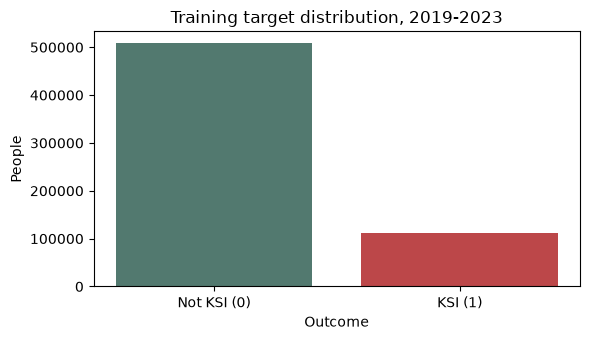

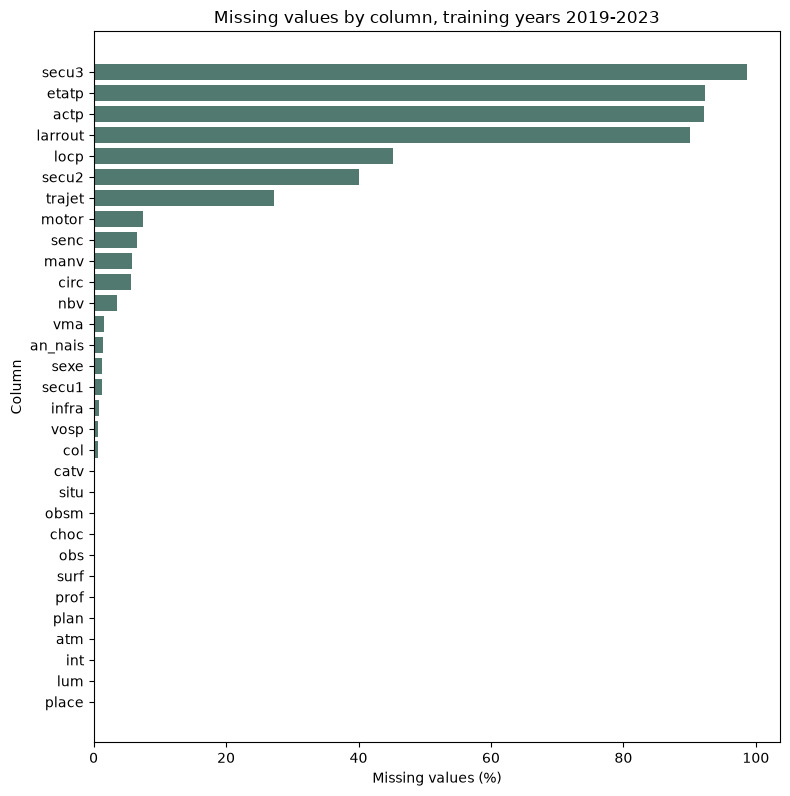

In [12]:
# Sections 3-4: verify M1 outputs and summarize training-only missingness / target balance.
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

from src.config import FIGURES_DIR, GROUP_COL, PROCESSED_DIR, TARGET, TRAIN_YEARS

persons_path = PROCESSED_DIR / "persons.parquet"
sample_path = PROCESSED_DIR / "persons_sample.parquet"
full_file = pq.ParquetFile(persons_path)
sample_file = pq.ParquetFile(sample_path)
assert full_file.metadata.num_rows == 871_115
assert sample_file.metadata.num_rows == 1_998
assert len(full_file.schema.names) == len(sample_file.schema.names) == 46
assert full_file.schema.names == sample_file.schema.names
print(f"persons.parquet: {full_file.metadata.num_rows:,} rows, {len(full_file.schema.names)} columns")
print(f"persons_sample.parquet: {sample_file.metadata.num_rows:,} rows, same schema")
print("Schema:", full_file.schema.names)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
missing_counts = pd.Series(0, index=full_file.schema.names, dtype="int64")
ksi_counts = pd.Series(0, index=[0, 1], dtype="int64")
train_rows = 0
train_year_counts = {}
for batch in full_file.iter_batches(batch_size=100_000):
    batch_df = batch.to_pandas()
    train_batch = batch_df.loc[batch_df["year"].isin(TRAIN_YEARS)]
    if train_batch.empty:
        continue
    train_rows += len(train_batch)
    missing_counts += train_batch.isna().sum().astype("int64")
    ksi_counts = ksi_counts.add(train_batch[TARGET].value_counts(), fill_value=0).astype("int64")
    for year, count in train_batch["year"].value_counts().items():
        year = int(year)
        train_year_counts[year] = train_year_counts.get(year, 0) + int(count)
assert train_rows == 619_552
missing_pct = (100 * missing_counts / train_rows).sort_values(ascending=False)
missing_summary = missing_pct[missing_pct > 0].rename("missing_%").to_frame()
target_summary = pd.DataFrame({"people": ksi_counts, "share_%": 100 * ksi_counts / train_rows})
print(f"Training rows counted in batches: {train_rows:,}; years: {dict(sorted(train_year_counts.items()))}")
display(target_summary.round(2))
display(missing_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(["Not KSI (0)", "KSI (1)"], ksi_counts.reindex([0, 1]).values, color=["#52796f", "#bc4749"])
ax.set(title="Training target distribution, 2019-2023", xlabel="Outcome", ylabel="People")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m2_target_distribution.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(8, max(4, 0.26 * len(missing_summary))))
plot_missing = missing_summary["missing_%"].sort_values()
ax.barh(plot_missing.index, plot_missing.values, color="#52796f")
ax.set(title="Missing values by column, training years 2019-2023", xlabel="Missing values (%)", ylabel="Column")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m2_missing_values.png", dpi=160)
plt.show()

## 5. Define and Verify Data Splits
The full dataset is split by configured year constants. Validation folds are stratified by KSI and grouped by accident ID; every fold reports sizes, validation prevalence, and overlap checks.

In [13]:
# Section 5: verify the full year split and accident-grouped validation.
from src.features.split import get_cv, get_splits

split_frame = pd.read_parquet(persons_path, columns=["year", TARGET, GROUP_COL, "lum"])
X_train_full, y_train_full, groups_train_full, X_test_full, y_test_full = get_splits(split_frame)
assert len(X_train_full) == len(y_train_full) == 619_552
assert len(X_test_full) == len(y_test_full) == 251_563
assert X_train_full.columns.tolist() == ["lum"]
assert not ({TARGET, "grav", GROUP_COL, "person_id", "id_vehicule", "year", "jour", "hrmn"} & set(X_train_full.columns))
print(f"Full split: train={len(X_train_full):,}; test={len(X_test_full):,}; training KSI rate={y_train_full.mean():.3%}")

fold_rows = []
for fold, (train_idx, valid_idx) in enumerate(get_cv().split(X_train_full, y_train_full, groups_train_full), start=1):
    overlap = set(groups_train_full.iloc[train_idx].unique()) & set(groups_train_full.iloc[valid_idx].unique())
    assert not overlap, f"Accident leakage in fold {fold}: {len(overlap)} groups"
    fold_rows.append({
        "fold": fold,
        "fit_people": len(train_idx),
        "validation_people": len(valid_idx),
        "validation_accidents": groups_train_full.iloc[valid_idx].nunique(),
        "validation_KSI_rate_%": 100 * y_train_full.iloc[valid_idx].mean(),
        "overlapping_accidents": len(overlap),
    })
fold_summary = pd.DataFrame(fold_rows).set_index("fold")
assert len(fold_summary) == 5 and fold_summary["overlapping_accidents"].eq(0).all()
display(fold_summary.round(3))

Full split: train=619,552; test=251,563; training KSI rate=18.029%


,fit_people,validation_people,validation_accidents,validation_KSI_rate_%,overlapping_accidents
fold,,,,,
1,495641,123911,54666,18.030,0
2,495642,123910,54559,18.030,0
3,495641,123911,54796,18.029,0
4,495643,123909,54576,18.029,0
5,495641,123911,54629,18.029,0


## 6. Implement Feature Engineering
Derived values are row-wise and do not estimate population statistics. The night KSI chart is descriptive and uses training years only.

Derived feature missingness, training years only:


,missing_%
age,1.35
hour,0.00
night,0.00
weekday,0.00
weekend,0.00
road_user,0.14
belt_or_helmet_recorded,13.99
equipment_none,13.99
is_overseas,0.00


KSI association by engineered night indicator (descriptive, not causal):


,people,KSI_rate_%
night,,
Day/evening (06:00-21:59),540354,17.25
Night (22:00-05:59),79198,23.32


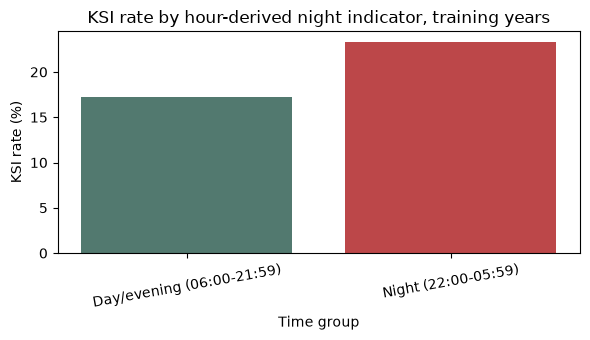

In [14]:
# Section 6: feature engineering and outcome association on training years only.
from src.features.build_features import add_features

feature_source_columns = [
    "year", TARGET, "an_nais", "hrmn", "mois", "jour", "dep", "catu", "catv", "secu1", "secu2"
]
feature_frame = pd.read_parquet(persons_path, columns=feature_source_columns)
feature_train = feature_frame.loc[feature_frame["year"].isin(TRAIN_YEARS)].copy()
del feature_frame
engineered_train = add_features(feature_train)
del feature_train
new_feature_columns = [
    "age", "hour", "night", "weekday", "weekend", "road_user",
    "belt_or_helmet_recorded", "equipment_none", "is_overseas",
]
feature_missing = (100 * engineered_train[new_feature_columns].isna().mean()).rename("missing_%").to_frame()
night_summary = engineered_train.groupby("night", observed=True)[TARGET].agg(people="size", KSI_rate="mean")
night_summary["KSI_rate_%"] = 100 * night_summary.pop("KSI_rate")
night_summary.index = night_summary.index.map({0.0: "Day/evening (06:00-21:59)", 1.0: "Night (22:00-05:59)"})
print("Derived feature missingness, training years only:")
display(feature_missing.round(2))
print("KSI association by engineered night indicator (descriptive, not causal):")
display(night_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(night_summary.index, night_summary["KSI_rate_%"], color=["#52796f", "#bc4749"])
ax.set(title="KSI rate by hour-derived night indicator, training years", xlabel="Time group", ylabel="KSI rate (%)")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m2_night_ksi_rate.png", dpi=160)
plt.show()
del engineered_train

## 7. Implement Preprocessing Pipelines
Only explicit, low-to-moderate-cardinality columns enter the encoders. Both variants are fitted inside diagnostic Pipelines on the sample training rows; held-out rows are transformed only.

In [15]:
# Section 7: fit both preprocessing variants within Pipelines on the sample training rows only.
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

from src.features.preprocess import build_preprocessor

sample_features = add_features(pd.read_parquet(sample_path))
X_sample_train, y_sample_train, groups_sample_train, X_sample_test, y_sample_test = get_splits(sample_features)
assert len(X_sample_train) == 1_503 and len(X_sample_test) == 495
forbidden_columns = {TARGET, "grav", "person_id", GROUP_COL, "id_vehicule", "id_usager", "year", "jour", "hrmn"}
assert not (forbidden_columns & set(X_sample_train.columns))
print(f"Sample split: train={len(X_sample_train):,}; test={len(X_sample_test):,}; X columns={X_sample_train.shape[1]}")

preprocessing_shapes = {}
for kind in ("linear", "tree"):
    preprocessor = build_preprocessor(kind)
    assert not hasattr(preprocessor, "transformers_")
    diagnostic_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("placeholder", DummyClassifier(strategy="prior")),
    ])
    diagnostic_pipeline.fit(X_sample_train, y_sample_train)
    fitted_preprocessor = diagnostic_pipeline.named_steps["preprocessor"]
    train_matrix = fitted_preprocessor.transform(X_sample_train)
    test_features = X_sample_test.head(100).copy()
    test_features.loc[test_features.index[0], "dep"] = "__unseen_department__"
    test_matrix = fitted_preprocessor.transform(test_features)
    preprocessing_shapes[kind] = train_matrix.shape[1]
    print(f"{kind}: train transformed={train_matrix.shape}; held-out transform={test_matrix.shape}; format={type(train_matrix).__name__}")
assert preprocessing_shapes["linear"] == preprocessing_shapes["tree"]
print("The forced unseen category transformed without error; no test labels were read.")

Sample split: train=1,503; test=495; X columns=48
linear: train transformed=(1503, 170); held-out transform=(100, 170); format=csr_matrix
tree: train transformed=(1503, 170); held-out transform=(100, 170); format=csr_matrix
The forced unseen category transformed without error; no test labels were read.


## 8. Smoke Tests and Validation
The interface checks below use the whole-accident M1 sample. The full-data checks above establish the agreed split and fold isolation. No held-out model performance is calculated.

In [16]:
# Section 8: logistic regression smoke fit on sample training rows only; no scores are computed.
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src.config import RANDOM_STATE

logistic_pipeline = Pipeline([
    ("preprocessor", build_preprocessor("linear")),
    ("model", LogisticRegression(
        solver="liblinear",
        class_weight="balanced",
        max_iter=1_000,
        random_state=RANDOM_STATE,
    )),
])
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    logistic_pipeline.fit(X_sample_train, y_sample_train)
print(
    "Logistic pipeline fit completed:",
    f"rows={len(X_sample_train):,}",
    f"transformed_features={logistic_pipeline.named_steps['preprocessor'].transform(X_sample_train).shape[1]:,}",
    f"iterations={logistic_pipeline.named_steps['model'].n_iter_.tolist()}",
)
print("This is an interface smoke test, not a model evaluation.")

Logistic pipeline fit completed: rows=1,503 transformed_features=170 iterations=[7]
This is an interface smoke test, not a model evaluation.


## 9. Document Decisions and Results

| Area | Decision | Reason |
|---|---|---|
| Split | 2019-2023 train/validation; 2024-2025 final test; shuffled stratified 5-fold CV grouped by `Num_Acc` | Preserves the agreed temporal holdout and prevents accident leakage. |
| Stateless features | `age`, hour-derived `night`, categorical `weekday`, `weekend`, M1 `road_user`, overseas flag | Computed from the row only; raw `year`, day, and time are excluded from model features. |
| Safety equipment | Keep `secu1`/`secu2` as categorical codes; derive `belt_or_helmet_recorded` only from documented codes 1/2 and `equipment_none` only from documented code 0; exclude `secu3` | Other code meanings are not defined in the available schema, so they remain unknown. M1 also observed `secu3` recording drift. |
| Missing values | Numeric median imputation with missing indicators; categorical `__MISSING__` category | Structural missingness in pedestrian/equipment fields can be informative. Valid zero codes stay categories. |
| Encoding | One-hot with `min_frequency=50`, `handle_unknown='infrequent_if_exist'`; omit `com` and `catv` | Bounds rare categories, prevents commune-level expansion, and avoids the M1 `road_user`/`catv` redundancy. |
| Scaling and imbalance | Scale numeric features only for `linear`; recommend model-level `class_weight='balanced'` | Keeps fitted transforms inside fold-fitted pipelines; no SMOTE. |
| Deferred | Feature selection and full leakage demonstration | Outside tonight's requested scope; do not select features before CV. |

### M3 integration order

`add_features` is stateless and runs before splitting. Then fit every preprocessor/model inside the estimator pipeline and pass `groups_train` to CV:

```python
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

from src.config import PROCESSED_DIR, RANDOM_STATE
from src.features.build_features import add_features
from src.features.preprocess import build_preprocessor
from src.features.split import get_cv, get_splits

persons = pd.read_parquet(PROCESSED_DIR / "persons.parquet")
featured = add_features(persons)
X_train, y_train, groups_train, X_test, y_test = get_splits(featured)
model = Pipeline([
    ("preprocess", build_preprocessor("linear")),
    ("classifier", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE)),
])
cv_results = cross_validate(
    model, X_train, y_train, cv=get_cv(), groups=groups_train,
    scoring="average_precision", n_jobs=1,
)
```

Use `build_preprocessor("tree")` for tree estimators. Keep `X_test` untouched until the final evaluation. The notebook's logistic fit is a sample-train interface smoke test only; no scores are reported. Generated figures are saved under `report/figures/m2_*.png`. All work remains uncommitted for review.